# Advanced Automation 2025/26 - Assignment 1

To be delivered until 2025-12-05 23:59:59.

**Submission Notes**:
- Create a folder in your group's GitHub repository to solve this assignment. Copy this notebook into that folder.
- You should commit regularly to your repository the answers to the questions in this notebook. If you do not, your grade will be penalized by 1/20 points.
- After running the entire notebook (including graphs and outputs), save the notebook as a .pdf file, by going to File - Print - Destination: Save as PDF.
- Create a .zip file containing both the .ipynb file (the notebook itself) and the .pdf and submit it in Fénix.

# Problem description

The dataset for this assignment contains information on students from two Portuguese secondary schools enrolled in a mathematics course.
Each row corresponds to one student and includes demographic and family background variables (e.g., basic personal and household characteristics), school-related variables (e.g., school context, study habits, past failures), behavioral and lifestyle indicators (e.g., free time, going out, alcohol use), and the grades for the three school periods, on a 0–20 scale.

The goal is to predict the performance of the students in the final period.
First, the problem will be approached as a classification task, predicting whether a student will pass (G3 >= 10) or fail (G3 < 10) the course.
Then, the problem will be approached as a regression task, predicting the actual final grade (G3).

A detailed description of all variables (family context, behavioral, school performance, etc.) is provided in the file `variable_description.txt`.

# Part 1 - Data exploration **(4.00)**

##### **1.1.** Load the dataset from the CSV file `mathematics_grades.csv`. **(0.25)**

In [1]:
import pandas as pd

df = pd.read_csv('mathematics_grades.csv')
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,failed
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,True
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,True
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,False
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,False
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,False


##### **1.2.** Identify the feature types of each variable in the dataset. **(1.50)**

In [2]:
import pandas as pd

df = pd.read_csv('mathematics_grades.csv')

info_df = pd.DataFrame({
    'Column': df.columns,
    'Dtype': df.dtypes
})

info_df.reset_index(drop=True, inplace=True)
info_df.index.name = '#'

print(f" {'#':<4} {'Column':<12} {'Dtype':<10}")
print(f" {'---':<4} {'------':<12} {'-----':<10}")

for i, row in info_df.iterrows():
    print(f" {i:<4} {row['Column']:<12} {row['Dtype']}")

 #    Column       Dtype     
 ---  ------       -----     
 0    school       object
 1    sex          object
 2    age          int64
 3    address      object
 4    famsize      object
 5    Pstatus      object
 6    Medu         int64
 7    Fedu         int64
 8    Mjob         object
 9    Fjob         object
 10   reason       object
 11   guardian     object
 12   traveltime   int64
 13   studytime    int64
 14   failures     int64
 15   schoolsup    object
 16   famsup       object
 17   paid         object
 18   activities   object
 19   nursery      object
 20   higher       object
 21   internet     object
 22   romantic     object
 23   famrel       int64
 24   freetime     int64
 25   goout        int64
 26   Dalc         int64
 27   Walc         int64
 28   health       int64
 29   absences     int64
 30   G1           int64
 31   G2           int64
 32   G3           int64
 33   failed       bool


##### **1.3** Check if the dataset has missing values. If so, discard any row that has a missing value. **(0.25)**

In [3]:
import pandas as pd

df = pd.read_csv('mathematics_grades.csv')

missing_values = df.isnull().sum()
total_missing = missing_values.sum()

print("Missing values per column:")
print(missing_values.to_string())

print(f"\nTotal missing values: {total_missing}")

Missing values per column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
failed        0

Total missing values: 0


##### **1.4.** Make a pairplot of the numerical variables, colored by the `failed` variable. **(0.50)**

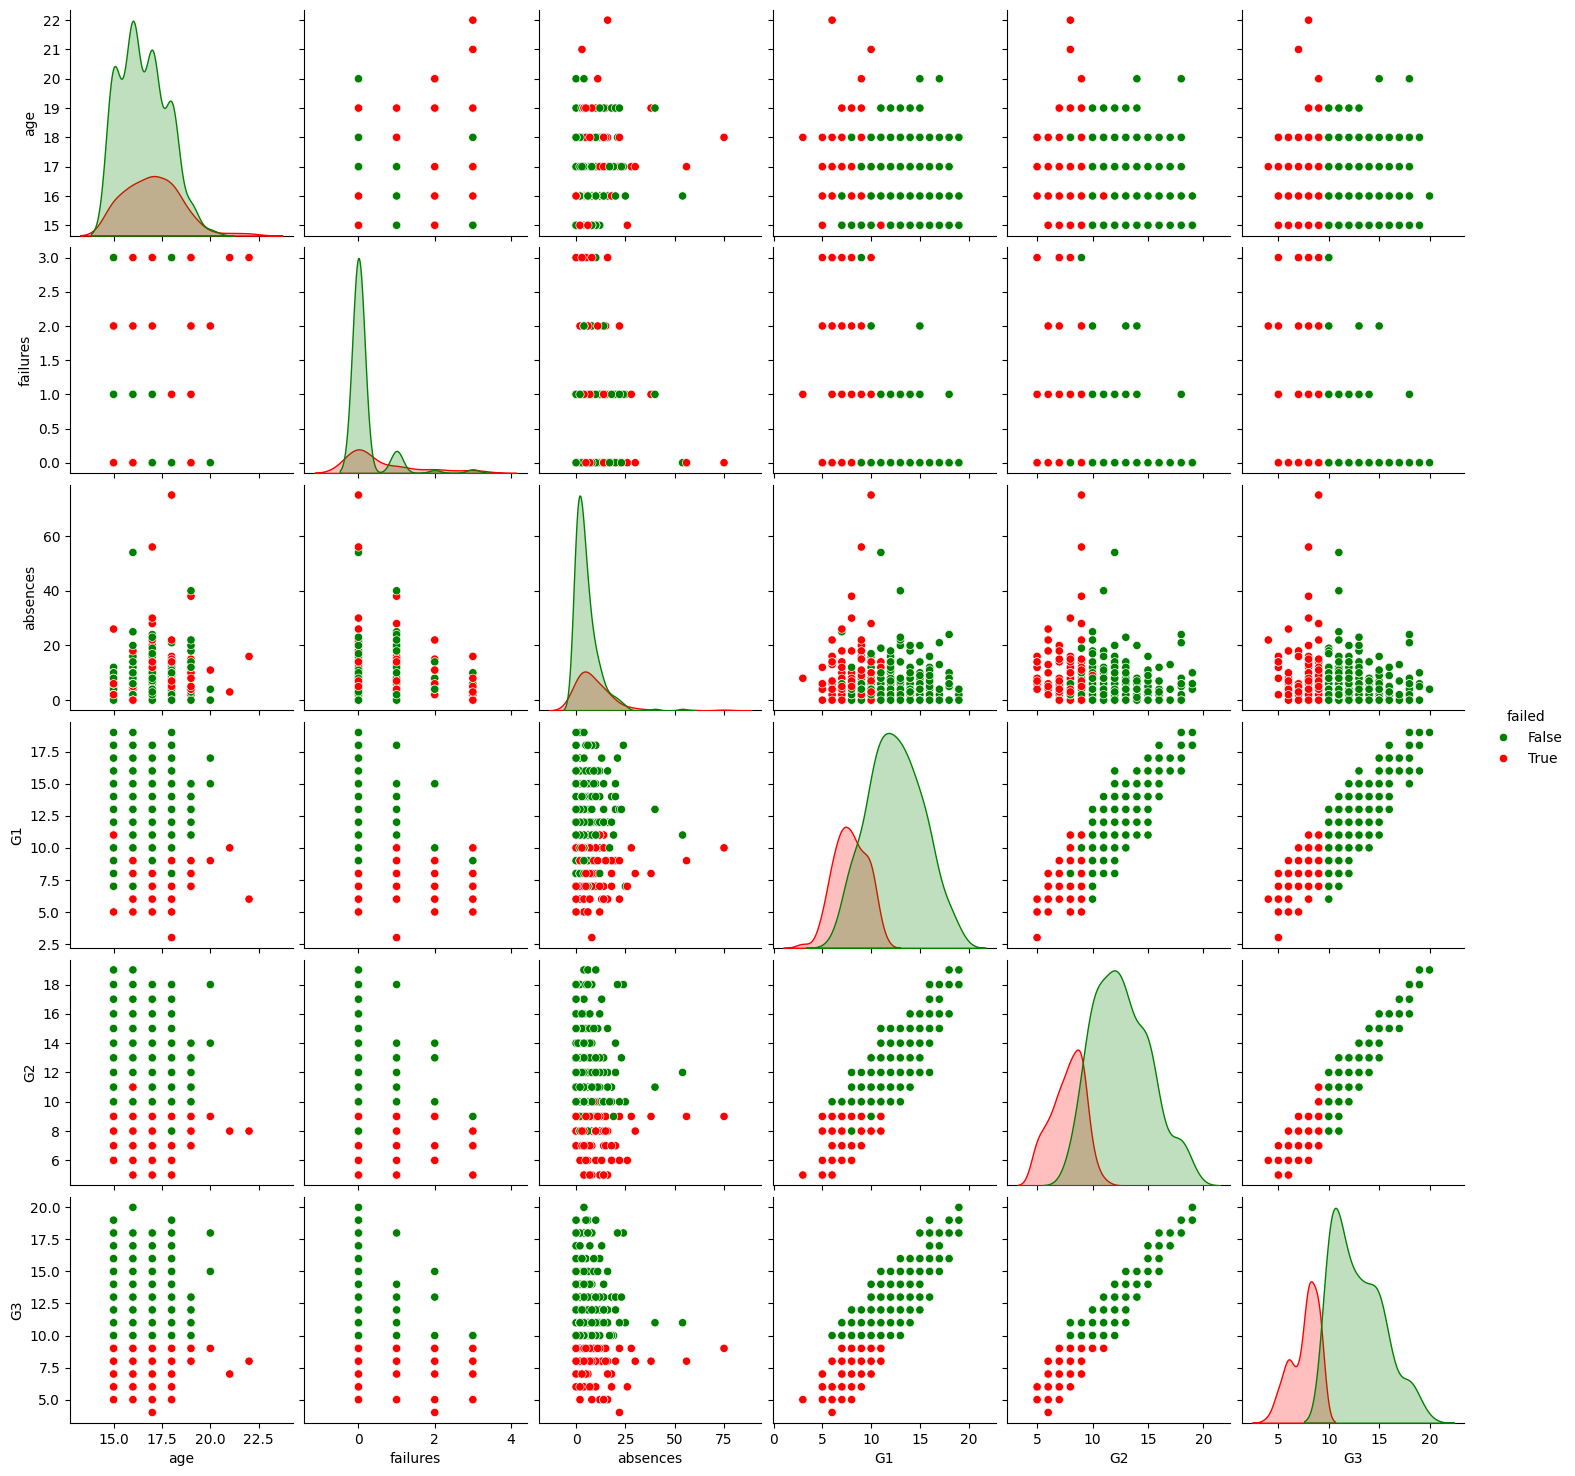

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('mathematics_grades.csv')

selected_cols = ['age', 'failures', 'absences', 'G1', 'G2', 'G3', 'failed']
df_subset = df[selected_cols]

sns.pairplot(df_subset, hue='failed', diag_kind='kde', palette={True: 'red', False: 'green'})
plt.savefig('numerical_pairplot.png')

##### **1.5.** Make bar plots for each categorical variable, showing the counts for each category, colored by the `failed` variable. **(0.50)**

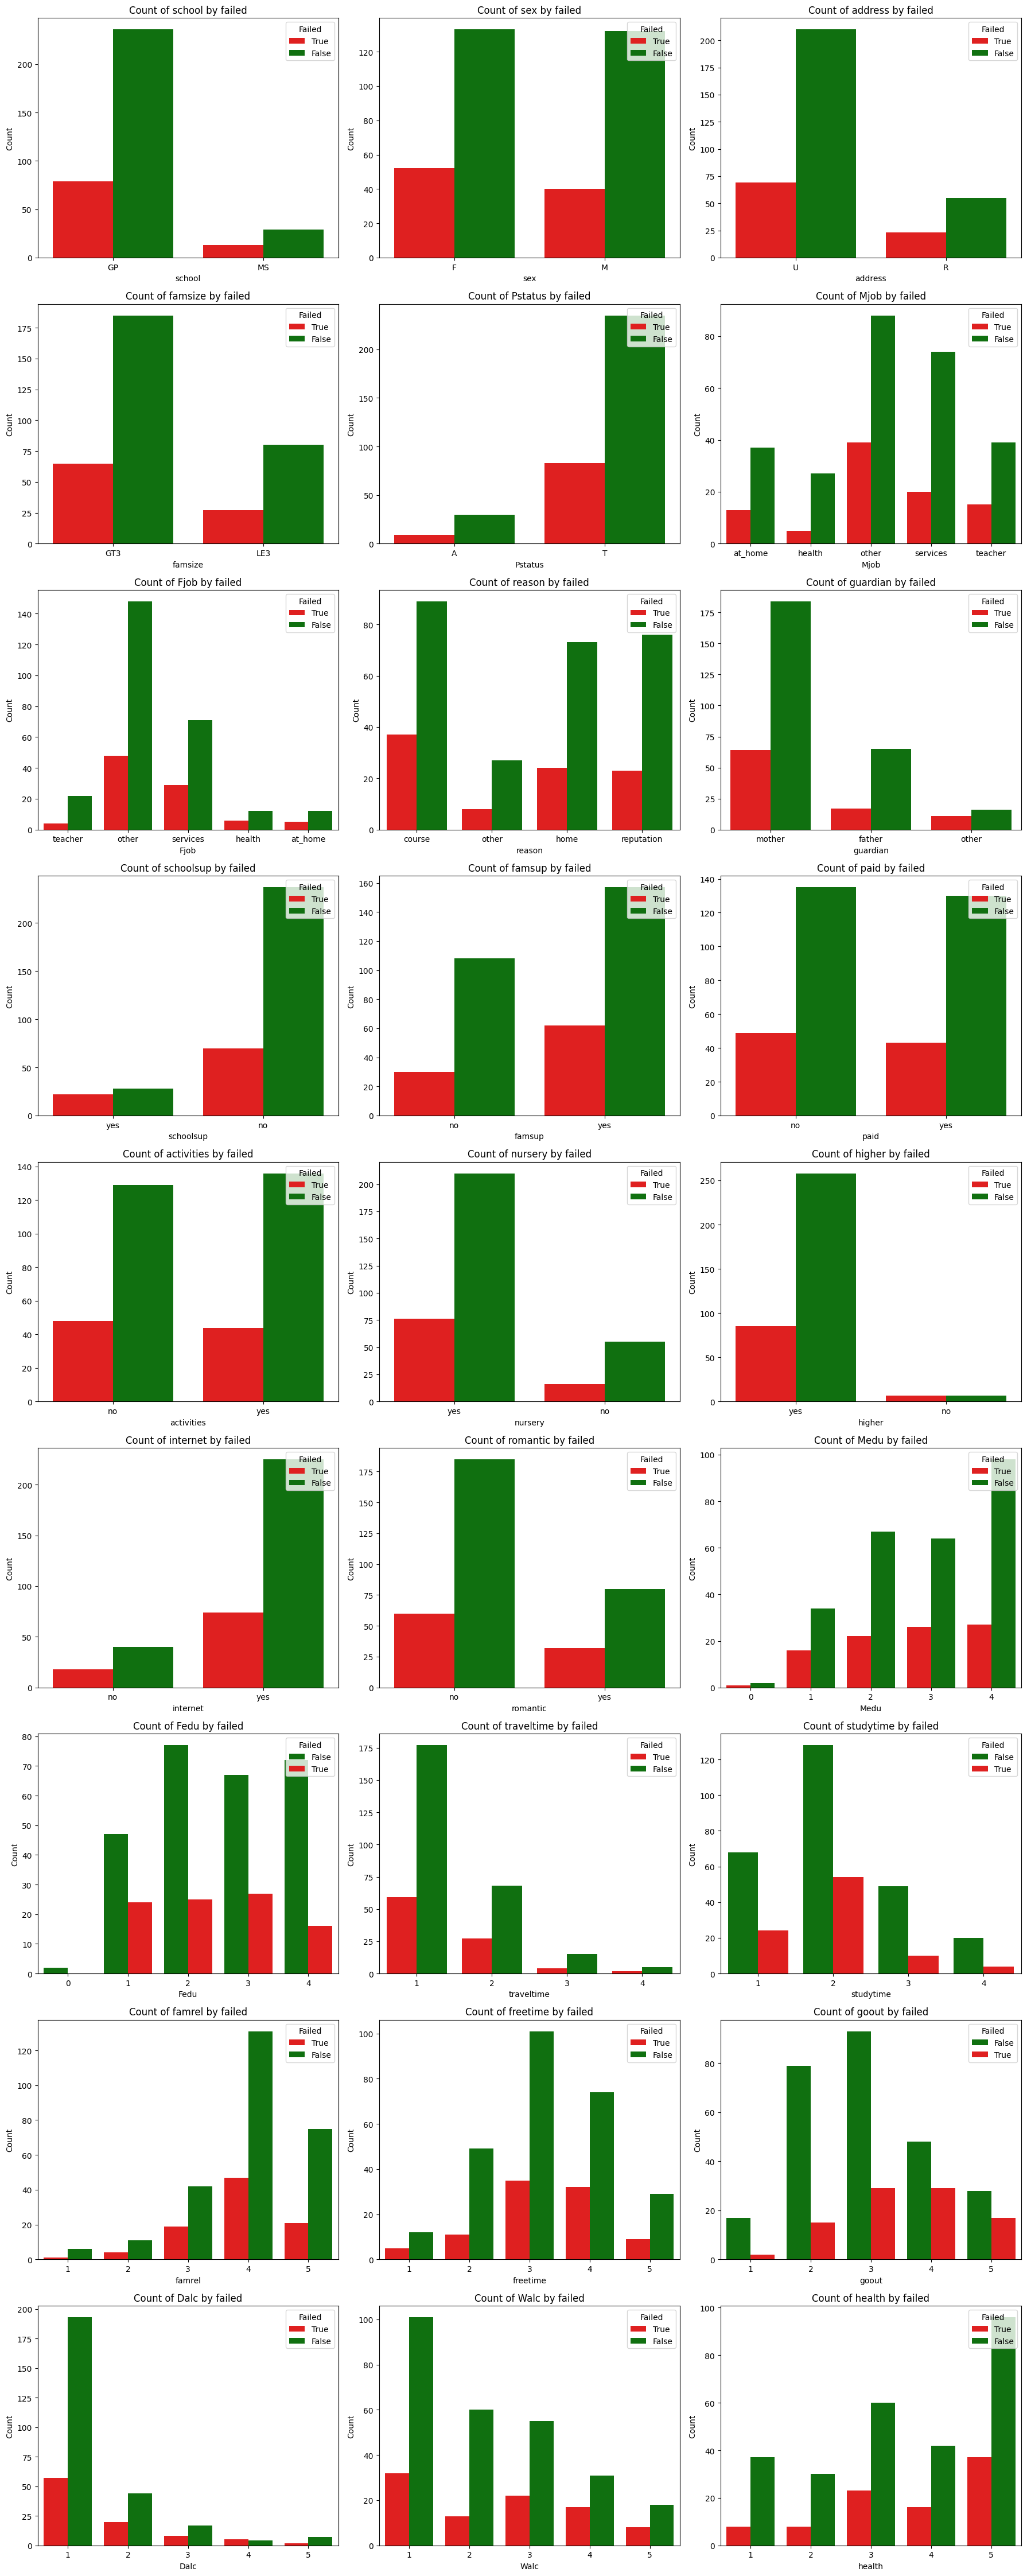

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math

df = pd.read_csv('mathematics_grades.csv')
df['failed'] = df['failed'].astype(str) 

nominal_cols = ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian',
                'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
ordinal_cols = ['Medu', 'Fedu', 'traveltime', 'studytime', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health']

all_cat_cols = nominal_cols + ordinal_cols
n_cols = 3
n_rows = math.ceil(len(all_cat_cols) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(all_cat_cols):

    sns.countplot(
        data=df, 
        x=col, 
        hue='failed', 
        ax=axes[i], 
        palette={'True': 'red', 'False': 'green'} 
    )
    
    axes[i].set_title(f'Count of {col} by failed')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')
    axes[i].legend(title='Failed', loc='upper right')

for i in range(len(all_cat_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.savefig('categorical_barplots.png')
plt.show()

##### **1.6.** In each school, how many students live in a rural area and do not have internet access at home? **(0.50)**

In [7]:
import pandas as pd

df = pd.read_csv('mathematics_grades.csv')

rural_no_internet = df[(df['address'] == 'R') & (df['internet'] == 'no')]

result = rural_no_internet.groupby('school').size()

print("Number of students living in rural areas without internet access per school:")
print(result)

Number of students living in rural areas without internet access per school:
school
GP    17
MS     7
dtype: int64


##### **1.7.** Split the dataset into a training set (80%) and a test set (20%). **(0.50)**

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('mathematics_grades.csv')

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

train_df.to_csv('train.csv', index=False)
test_df.to_csv('test.csv', index=False)

print(f"Original dataset shape: {df.shape}")
print(f"Training set shape: {train_df.shape}")
print(f"Test set shape: {test_df.shape}")

Original dataset shape: (357, 34)
Training set shape: (285, 34)
Test set shape: (72, 34)


# Part 2 - Classification **(7.50)**

##### You'll start by approaching the problem as a classification task, predicting whether a student will pass (G3 >= 10) or fail (G3 < 10) the course. Consider the variable `failed` as the target variable.

##### **2.1.** Which performance metric do you think are most important for this prediction task, and why? Justify your answer in the context of supporting students who may struggle academically. **(2.00)**

The model will be predicting the variable “failed” whereas true or false (1/0). After running the model, we will find that the predictions aren’t all correct, so we use a confusion matrix to summarize the errors of the model. When the model guesses are correct, we obtain True Positives (TP) and True Negatives (TN), but when it fails to predict we obtain False Positives (FP) and False Negatives (FN). In our case, being a FN means the model predicts that a student will pass but actually fails, on other hand being a FP means the model predicts that a student will fail when in reality he passes. By analyzing the consequences, the most concerning outcome is FN, meaning that the student will not get a chance to be supported and helped, which could lead to academic failure. Being a FP it’s not as concerning because the only downside would be to consume unnecessary school resources, but it would be harmless to the student. 
The main goal will be monitoring the number of FN and the most suitable metric to do it’s the Recall.

##### **2.2.** Build a logistic regression model to predict whether a student will pass or fail the course, using as predictor the feature `absences`. Evaluate the performance of the model on the test set using a confusion matrix, accuracy, precision, recall, f1-score and the metric you selected in question 2.1. **(0.50)**

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

df = pd.read_csv('mathematics_grades.csv')
X = df[['absences']]
y = df['failed'] 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")

Confusion Matrix:
 [[53  0]
 [18  1]]
Accuracy:  0.7500
Precision: 1.0000
Recall:    0.0526
F1-Score:  0.1000


##### **2.3.** The model you built in question 2.2 likely does not perform very well. Explain why this is the case, considering the distribution of the predictor and the response. How can you improve the model? **(2.00)**

The poor results of the model are due to the inability to predict failing students (Recall ≈ 5%). Main causes to the inability might: class imbalance and weak discriminative power of the predictor.
The dataset is highly imbalanced with several more students passing than failing. The standard logistic regression algorithm tries to maximize the overall accuracy, so when presented with an imbalanced dataset, this model learns that always predicting the majority class ("Pass") is the safest strategy to minimize total error. This results in a "conservative" model, which will get high accuracy (75%), but will fail in its main purpose of detecting the minority class: failing students.
Relying only on the “absence” variable is poor separator of the two classes: many passing students may still have a moderate number of absences, and some of the failures might have few. Since the distributions of absences for "passing" and "failing" students are much the same, the model was unable to find a threshold to distinguish between them effectively.

The model can be improved by:

•	Handle imbalance using Class weights: setting class_weight='balanced' will result in a larger penalty for the model on misclassification of the minority class.

•	Threshold Adjustment: Instead of adhering to the default probability threshold of 0.5, lower the decision threshold-for example, classify "Fail" when the probability is > 0.2-to give more importance to Recall and catch more at-risk students.

•	Improve Predictors: Add more variables to improve classification.


##### **2.4.** Consider now the variable `studytime` as the predictor and assume it is numerical. Build a logistic regression model to predict whether a student will pass or fail the course. Evaluate the performance of the model on the test set using a confusion matrix, accuracy, precision, recall, f1-score and the metric you selected in question 2.1. **(0.50)**

Note: Use `sklearn.linear_model.LogisticRegression(class_weight='balanced')` for your logistic regression model.

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

df = pd.read_csv('mathematics_grades.csv')
X = df[['studytime']]
y = df['failed']       

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression(class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")
print(f"Coefficient (studytime): {model.coef_[0][0]:.4f}")

Confusion Matrix:
 [[11 42]
 [ 4 15]]
Accuracy:  0.3611
Precision: 0.2632
Recall:    0.7895
F1-Score:  0.3947
Coefficient (studytime): -0.2353


##### **2.5.** Repeat question 2.4, but now considering `studytime` as a categorical variable. **(0.50)**

In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

df = pd.read_csv('mathematics_grades.csv')

X = pd.get_dummies(df[['studytime']].astype(str), drop_first=True)
y = df['failed']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression(class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")

print("\nCoeficientes (Referência: studytime_1):")
for col, coef in zip(X.columns, model.coef_[0]):
    print(f"{col}: {coef:.4f}")

Confusion Matrix:
 [[25 28]
 [ 9 10]]
Accuracy:  0.4861
Precision: 0.2632
Recall:    0.5263
F1-Score:  0.3509

Coeficientes (Referência: studytime_1):
studytime_2: 0.2546
studytime_3: -0.8153
studytime_4: -0.1381


##### **2.6.** What is the difference between the two models you built in questions 2.4 and 2.5? Plot the predictions of each model over the range of `studytime` values in the test set. What are the advantages and disadvantages of each approach? **(2.00)**


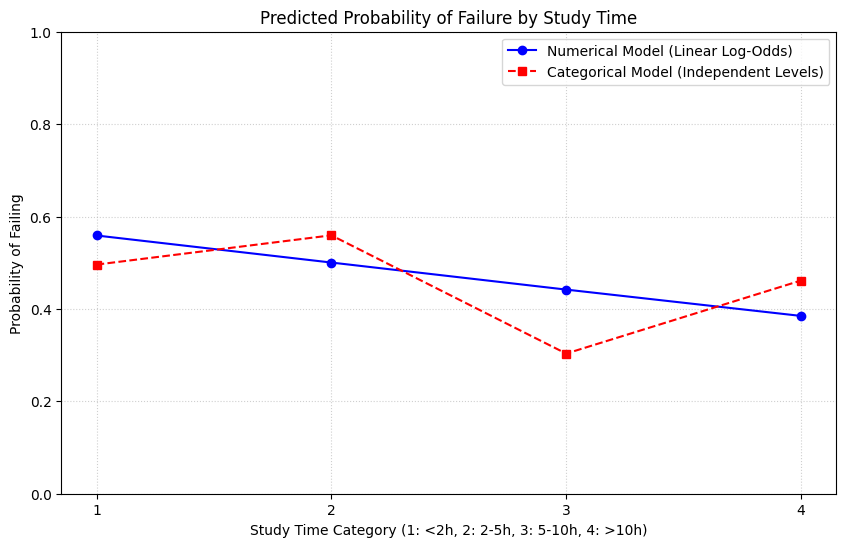

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

df = pd.read_csv('mathematics_grades.csv')
y = df['failed']

X_num = df[['studytime']]
X_train_num, X_test_num, y_train_num, y_test_num = train_test_split(X_num, y, test_size=0.2, random_state=42)
model_num = LogisticRegression(class_weight='balanced', random_state=42)
model_num.fit(X_train_num, y_train_num)

X_cat = pd.get_dummies(df['studytime'], prefix='studytime', drop_first=True)

X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(X_cat, y, test_size=0.2, random_state=42)
model_cat = LogisticRegression(class_weight='balanced', random_state=42)
model_cat.fit(X_train_cat, y_train_cat)

study_values = [1, 2, 3, 4]

proba_num = model_num.predict_proba(pd.DataFrame({'studytime': study_values}))[:, 1]

dummy_data = {
    'studytime_2': [0, 1, 0, 0],
    'studytime_3': [0, 0, 1, 0],
    'studytime_4': [0, 0, 0, 1]
}
X_pred_cat = pd.DataFrame(dummy_data)
proba_cat = model_cat.predict_proba(X_pred_cat)[:, 1]

plt.figure(figsize=(10, 6))

plt.plot(study_values, proba_num, marker='o', linestyle='-', label='Numerical Model (Linear Log-Odds)', color='blue')

plt.plot(study_values, proba_cat, marker='s', linestyle='--', label='Categorical Model (Independent Levels)', color='red')

plt.title('Predicted Probability of Failure by Study Time')
plt.xlabel('Study Time Category (1: <2h, 2: 2-5h, 3: 5-10h, 4: >10h)')
plt.ylabel('Probability of Failing')
plt.ylim(0, 1)
plt.xticks(study_values)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.savefig('studytime_comparison.png')
plt.show()

A key difference between the two models is the way they model the relationship between studytime and probability of failure. The numeric model from question 2.4 assumes a linear relationship in log-odds space, which corresponds to a fixed rate of change: it forces probability of failure to drop monotonically with increasing study time from 1 to 4. That assumes the "benefit" of going from level 1 to 2 is roughly comparable to that of going from 2 to 3. The categorical model from question 2.5 considers each level of study time as an independent bucket - effectively dummy variables for each category. No assumptions about order or magnitude are made, so this model learns a unique risk probability for each specific group.

The numerical approach has the advantage of simplicity and robustness, as it borrows strength across all data points to estimate a general trend. Its major disadvantage is rigidity, it cannot capture nonlinear pattern such as if "too much" studying were actually associated with higher failure due to anxiety or lack of efficiency. The categorical approach offers the advantage of flexibility, thus being able to spot irregular patterns, while its major disadvantage is the risk of overfitting, especially with small sample sizes for particular categories, where a few outliers can mess with the prediction for this entire group.

# Part 3 - Regression (3.50)

##### In this part of the assignment, you'll approach the problem as a regression task, predicting the actual final grade `G3`. Use the same training and test sets you created in Part 1.

##### **3.1.** Build a linear regression model to predict the final grade `G3`, using as predictor the feature `G2`. Evaluate the performance of the model on the test set using Mean Squared Error (MSE) and R-squared ($R^2$). **(0.50)**

In [13]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

X_train = train_df[['G2']]
y_train = train_df['G3']
X_test = test_df[['G2']]
y_test = test_df['G3']

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared (R^2):      {r2:.4f}")

Mean Squared Error (MSE): 0.6854
R-squared (R^2):      0.9289


##### **3.2.** Print the equation of the model you built in question 3.1. Plot the predictions of the model as a function of the inputs, along with the actual data points from the test set. Interpret the coefficients of the model. **(1.00)**


Intercept: 0.2750
Slope (Coefficient): 0.9897
Equation: G3 = 0.2750 + 0.9897 * G2


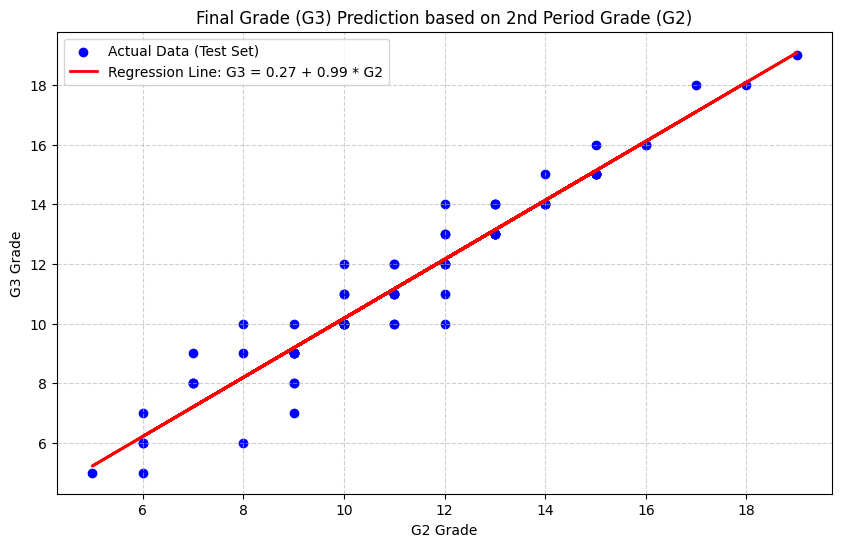

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

X_train = train_df[['G2']]
y_train = train_df['G3']
X_test = test_df[['G2']]
y_test = test_df['G3']

model = LinearRegression()
model.fit(X_train, y_train)

intercept = model.intercept_
slope = model.coef_[0]

y_pred = model.predict(X_test)

plt.figure(figsize=(10, 6))
plt.scatter(X_test, y_test, color='blue', label='Actual Data (Test Set)')
plt.plot(X_test, y_pred, color='red', linewidth=2, label=f'Regression Line: G3 = {intercept:.2f} + {slope:.2f} * G2')

plt.title('Final Grade (G3) Prediction based on 2nd Period Grade (G2)')
plt.xlabel('G2 Grade')
plt.ylabel('G3 Grade')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('linear_regression_plot.png')

print(f"Intercept: {intercept:.4f}")
print(f"Slope (Coefficient): {slope:.4f}")
print(f"Equation: G3 = {intercept:.4f} + {slope:.4f} * G2")

The model indicates an extremely strong positive linear relationship between the second period grade and the final grade. This is supported by the coefficient 0.9897 (approximately 1), indicating that with every increase in a student's G2 grade by 1 point, their G3 grade is expected to increase practically by the same amount of 0.99 points. This means the final grade is almost determined by the grade obtained immediately before it, with very little change happening in the final period. The intercept is 0.2750, which is for a baseline adjustment, since a student who would have a G2 of 0 would be predicted to have a G3 of approximately 0.28, which is very negligible, further reinforcing the 1-to-1 nature of the relationship.

##### **3.3.** Build a linear regression model to predict the final grade `G3`, using as predictors all features except the variables related to the grades (`G1`, `G2`, `G3`, `failed`). Explain the choices you made. Evaluate the performance of the model on the test set using Mean Squared Error (MSE) and R-squared ($R^2$). Plot the predicted vs actual values of `G3` for the test set. **(1.00)**

In [15]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

drop_cols = ['G1', 'G2', 'G3', 'failed']

X_train_raw = train_df.drop(columns=drop_cols)
y_train = train_df['G3']

X_test_raw = test_df.drop(columns=drop_cols)
y_test = test_df['G3']

combined_X = pd.concat([X_train_raw, X_test_raw], keys=['train', 'test'])
combined_X_encoded = pd.get_dummies(combined_X, drop_first=True)

X_train = combined_X_encoded.loc['train']
X_test = combined_X_encoded.loc['test']

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("--- Model Performance (Excluding G1, G2) ---")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared (R2): {r2:.4f}")

--- Model Performance (Excluding G1, G2) ---
Mean Squared Error (MSE): 7.6908
R-squared (R2): 0.2017


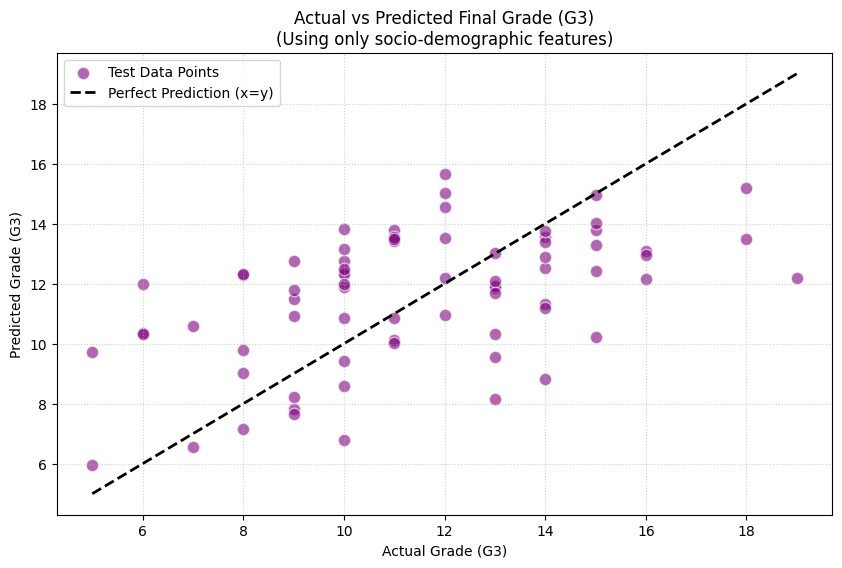

In [16]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred, color='purple', alpha=0.6, edgecolors='w', s=80, label='Test Data Points')

min_val = min(min(y_test), min(y_pred))
max_val = max(max(y_test), max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--', linewidth=2, label='Perfect Prediction (x=y)')

plt.title('Actual vs Predicted Final Grade (G3)\n(Using only socio-demographic features)')
plt.xlabel('Actual Grade (G3)')
plt.ylabel('Predicted Grade (G3)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

##### **3.4.** In terms of application, what is the difference between building a model to predict student performance using the grades of the previous periods (as in question 3.1) versus using other features (as in question 3.3)? When would each approach be more appropriate? **(1.00)**

The two models serve very different purposes. 
The grades-based model of Question 3.1 is a "late-stage" predictor, it relies on immediate past performance (G2), which is highly correlated with the final grade. This approach is suitable for short-term forecasting, for example to identify students before a final exam, who are statistically certain to fail given their current trajectory, in order to provide the students, the help that they’ll need to pass the exam. This is precise but reactive.

The features-based model of Question 3.3 is an "early-warning", it relies exclusively on socio-demographic and behavioral data from students, making it possible to deploy the model at the beginning of the school year, long before exams are given. That’s a more preventive approach than the one from 3.1, helping to identify students in the beginning of the year whose background or habits put them at risk so that long-term support can be provided to change their trajectory well before they ever earn a bad grade. It’s less accurate, but it’s arguably more valuable to change outcomes than to predict them.

# Part 4 - Cross-validation (4.00)

##### **4.1.** Explain the concept of cross-validation and its importance in evaluating machine learning models. **(1.00)**

Cross-validation is a statistical technique that would estimate the performance of machine learning models by resampling the available data in such a way that the evaluation is robust and does not depend on a single, way of randomly splitting the data into training and testing sets.
In general, the importance of cross-validation lies in three key areas: robustness, data efficiency, and overfitting detection. 
Most fundamentally, it ensures the robustness and reliability of the resulting score-one does not get a "lucky" or "unlucky" split. Instead of relying on one train-test division that may yield an unusually high or low accuracy by averaging results over k folds, this gives a better estimate of true performance on unseen data. 
It serves as a means of diagnosing overfitting. When a model just memorizes training data overfits, performing very well on training folds but then poorly on the validation folds; this is high variance, which absolutely confirms that the model has overfitted.


##### **4.2.** Describe how K-fold cross-validation works. What values of K should be used? Justify. **(1.00)**

K-Fold Cross-Validation Works K-fold cross-validation works by randomly shuffling the dataset and then splitting it into K equal-sized groups called "folds." The process then proceeds iteratively: for each unique fold, the algorithm treats that particular fold as the test set (holdout) and the remaining K−1 folds combined as the training set. A model is trained on this composite training set and tested on the holdout fold. This process repeats K times, ensuring every single data point is used for testing exactly once and for training K−1 times. Finally, the performance metrics (like Accuracy or MSE) of all K runs are averaged to arrive at a single, reliable estimate of model performance.

##### **4.3.** Explain how K-Fold cross-validation should be done to choose the classification threshold for the logistic regression model of Part 2. **(2.00)**

To choose the classification threshold using K-Fold cross-validation, we treat the threshold itself as a hyperparameter to be tuned rather than accepting the default 0.5 value. We define a range of candidate thresholds and perform the complete K-Fold cycle for each of them. Inside the cross-validation loop, at every fold, the model should be trained on the K−1 training folds and then used to predict probabilities on the validation fold. Then we apply the particular candidate threshold to these probabilities to classify students and calculate the target metric for that fold. After iterating through all folds, we compute the average Recall for that specific threshold. This procedure is repeated for every candidate threshold in our range. Then we compare the average score and select the threshold that yielded the highest average Recall. This optimized threshold is then applied to the final model to make predictions on the test set, ensuring that the sensitivity of our model is maximized robustly without overfitting to a single train-test split.

# Part 5 - GitHub (1.00)

##### **5.1.** Describe how your group used GitHub to track changes throughout the project and explain why maintaining a clear change history is important in data analysis and machine learning work. **(1.00)**

Our group used GitHub as a point of contact for the collaboration and version control of code, implementing the "Feature Branch Workflow" in an organized manner. Each member of the group worked on separate branches that were task-specific.
Maintaining a clear change history is important in data analysis and machine learning so that work is reproducible and experiments can be traced later. Unlike normal software development, Machine Learning consists of an iterative experimentation process, where one small change to data preprocessing or model parameters can make huge differences in results. A solid history allows the group to identify exactly which version of the code created a specific set of results, thus enabling us to roll back to prior successful models should a new approach fail.